In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.14.1+cpu
Device : cpu


# Chargement du dataset


In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


# Création, entrainement et évaluation du modèle discriminatif

Époque 1/3 - Perte : 0.4165
Époque 2/3 - Perte : 0.1940
Époque 3/3 - Perte : 0.1394
Précision sur le jeu de test : 96.14 %


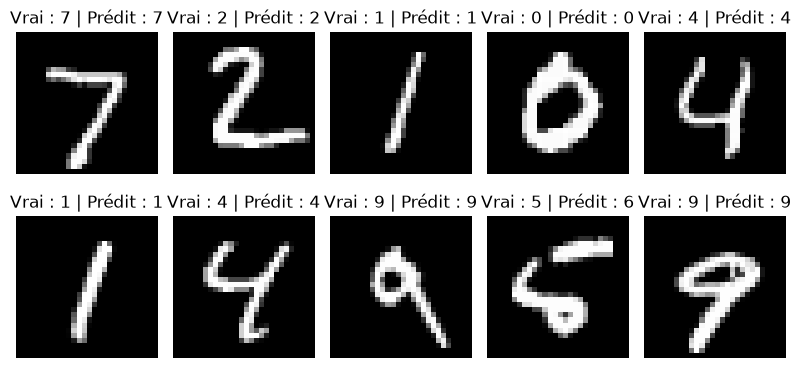

In [4]:
# Le modèle discriminatif apprend à associer chaque image à une classe.
# Ici, il doit reconnaître les 10 chiffres du jeu de données MNIST.
class ClassifieurMNIST(nn.Module):
    def __init__(self):
        super().__init__()

        # Flatten transforme chaque image 28 x 28 en un vecteur de 784 valeurs.
        self.reseau = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, images):
        return self.reseau(images)


classifieur = ClassifieurMNIST().to(device)

# CrossEntropyLoss est adaptée à une classification multi-classe.
# Le modèle renvoie des logits : il ne faut donc pas ajouter Softmax ici.
fonction_perte = nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(classifieur.parameters(), lr=1e-3)


def entrainer_modele(model, loader, nombre_epochs=3):
    """Entraîne le modèle et affiche la perte moyenne de chaque époque."""
    model.train()

    for epoch in range(nombre_epochs):
        perte_totale = 0.0

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            # Une passe avant produit les scores des 10 classes.
            scores = model(images)
            perte = fonction_perte(scores, labels)

            # On calcule les gradients puis on met à jour les paramètres.
            optimiseur.zero_grad()
            perte.backward()
            optimiseur.step()

            perte_totale += perte.item()

        perte_moyenne = perte_totale / len(loader)
        print(f"Époque {epoch + 1}/{nombre_epochs} - Perte : {perte_moyenne:.4f}")


@torch.no_grad()
def evaluer_modele(model, loader):
    """Calcule la précision du modèle sans modifier ses paramètres."""
    model.eval()
    nombre_predictions_correctes = 0
    nombre_images = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        scores = model(images)
        predictions = scores.argmax(dim=1)
        nombre_predictions_correctes += (predictions == labels).sum().item()
        nombre_images += labels.size(0)

    return nombre_predictions_correctes / nombre_images


# Entraînement sur les images et labels du jeu d'apprentissage.
entrainer_modele(classifieur, train_loader, nombre_epochs=3)

# Évaluation sur des images jamais utilisées pour l'entraînement.
precision = evaluer_modele(classifieur, test_loader)
print(f"Précision sur le jeu de test : {100 * precision:.2f} %")


# On affiche quelques prédictions pour vérifier concrètement le résultat.
images, labels = next(iter(test_loader))
with torch.no_grad():
    predictions = classifieur(images.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Vrai : {labels[i].item()} | Prédit : {predictions[i].item()}")
    ax.axis("off")
        
plt.tight_layout()
plt.show()